# Function hooks

Goal: the Manning friction of a 1-D shallow-water model supplied as a JAX function.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import zoomy_core.model.initial_conditions as IC
from zoomy_core.mesh import LSQMesh
from zoomy_core.misc.misc import ZArray
from zoomy_core.model.boundary_conditions import BoundaryConditions, FromModel
from zoomy_core.model.models import SWE
from zoomy_core.numerics import NumericalSystemModel
from zoomy_core.symsolver.hooks import hook
from zoomy_core.systemmodel.system_model import SystemModel
from zoomy_jax.symsolver.solver import SymbolicHyperbolicSolverJax

In [2]:
class SWEManningHook(SWE):
    def source(self):
        return ZArray([[0], [0], [hook("manning")(self.Q.h, self.Q.hu)]])

In [3]:
def manning(h, hu):
    return -9.81 * 0.03**2 * hu * jnp.sqrt(hu * hu + 1e-12) / h ** (7 / 3)

In [4]:
def simulate(model_class, functions=None):
    walls = BoundaryConditions([FromModel(tag=t, definition="wall") for t in ("left", "right")])
    sm = SystemModel.from_model(model_class(dimension=1, parameters={"n_m": 0.03}, boundary_conditions=walls))
    sm.initial_conditions = IC.UserFunction(function=lambda x: np.array([0 * x[0], 1 + 0.2 * np.exp(-(x[0] - 5) ** 2), 0.5 + 0 * x[0]]))
    mesh = LSQMesh.create_1d(domain=(0, 10), n_inner_cells=100)
    solver = SymbolicHyperbolicSolverJax(time_end=1.0, cfl=0.9, functions=functions)
    Q0, Qaux0 = solver.setup(mesh, NumericalSystemModel.from_system_model(sm))
    return np.asarray(mesh.cell_centers[0, :100]), np.asarray(solver.run(Q0, Qaux0)[1])

In [5]:
x, Q_hook = simulate(SWEManningHook, functions={"manning": manning})
x, Q_builtin = simulate(SWE)

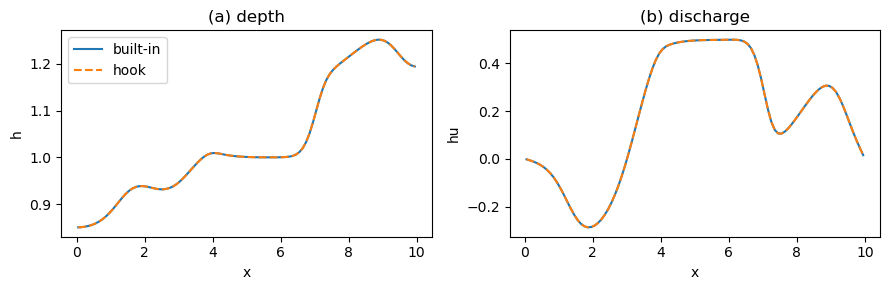

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for Q, label, style in ((Q_builtin, "built-in", "-"), (Q_hook, "hook", "--")):
    ax[0].plot(x, Q[1], style, label=label)
    ax[1].plot(x, Q[2], style, label=label)
ax[0].set(xlabel="x", ylabel="h", title="(a) depth")
ax[1].set(xlabel="x", ylabel="hu", title="(b) discharge")
ax[0].legend()
fig.tight_layout()

In [7]:
assert np.abs(Q_hook - Q_builtin).max() <= 1e-13